
# Simulation of emersion, acquisition timing, NDVI, and chlorophyll calibration

This notebook simulates how spatial chlorophyll distribution, migration speed,
acquisition timing, measurement noise, sample size, and calibration transfer
disturb an ideal NDVI–chlorophyll relationship.

The simulation uses **May 4, 2026** Brunswick elevation and emersion rasters.

Core assumptions:

- True chlorophyll is uniform from 0 to 80 mg m⁻².
- Full-expression NDVI is linear from 0 to 0.3.
- Migration affects NDVI only.
- Standard migration rises for 3 hours, plateaus for 2 hours, and declines
  for 5 hours.
- Migration speeds range from `1/sqrt(5)` to `sqrt(5)`.
- Exposure is always greater than one hour.


## Setup

In [1]:

%load_ext autoreload
%autoreload 2

import os
import sys
from itertools import product
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import rasterio

import config
import hatfield_funcs as hf

plt.style.use("default")
%config InlineBackend.figure_format = "retina"

project_root = Path("../..").resolve()
sys.path.insert(0, str(project_root / "src"))


In [2]:

if os.getenv("GA_STORAGE_ACCOUNT_NAME") is None:
    raise RuntimeError(
        "Set GA_STORAGE_ACCOUNT_NAME before running this notebook."
    )

hf.config.configure_azure()
hf.config.configure_data_root_path(config.CONTAINER_NAME)
os.environ.setdefault("GDAL_CACHEMAX", "512")


'512'

## Parameters

In [3]:

SIMULATION_DATE = pd.Timestamp("2026-05-04")
N_POINTS = 10_000
RANDOM_SEED = 42

path_elevation_raster_chart_datum = (
    "data/raw_clean/bathymetry/"
    "brunswick_bathymetry_clipped_cd.tif"
)
path_emersion_time_raster = (
    "data/processed/imagery_contextual/"
    "brunswick_emersion_time_20260504.tif"
)

MIN_NDVI, MAX_NDVI = 0.0, 0.3
MIN_CHLA_MGM2, MAX_CHLA_MGM2 = 0.0, 80.0

STANDARD_TIME_TO_PLATEAU_HR = 3.0
STANDARD_PLATEAU_DURATION_HR = 2.0
STANDARD_DECLINE_DURATION_HR = 5.0

MIGRATION_SPEED_RATIO = 5.0
SLOWEST_SPEED = 1.0 / np.sqrt(MIGRATION_SPEED_RATIO)
FASTEST_SPEED = np.sqrt(MIGRATION_SPEED_RATIO)

TARGET_MEAN_EXPOSURE_HR = 3.5
MIN_EXPOSURE_HR = 1.0
MIN_EXPOSURE_EPSILON_HR = 1e-3

ACQUISITION_WINDOWS_HR = {
    "small": 1.0,
    "large": 6.0,
}

SPATIAL_RANK_NOISE_SD = 0.5
ACQUISITION_ORDER_NOISE_SD = 0.08

NOISE_NDVI_PC = 15.0
NOISE_CHLA_PC = 15.0

DENSITY_CASES = ("random", "higher-high-elev")
MIGRATION_CASES = ("random", "faster-low-elev")
ACQUISITION_CASES = (
    "random",
    "first-low-elev",
    "first-high-elev",
)
WINDOW_CASES = ("small", "large")
NOISE_CASES = ("none", "applied")

SAMPLE_SIZES = [
    10, 20, 30, 40, 50,
    60, 70, 80, 90, 100,
    300, 500, 1000,
]
N_REPETITIONS = 500

EXAMPLE_SCENARIO = {
    "density": "higher-high-elev",
    "migration": "faster-low-elev",
    "acquisition": "first-low-elev",
    "window": "large",
    "noise": "applied",
}

ideal_slope = (
    (MAX_CHLA_MGM2 - MIN_CHLA_MGM2)
    / (MAX_NDVI - MIN_NDVI)
)
ideal_intercept = 0.0

print(f"Ideal slope: {ideal_slope:.6f}")
print(
    f"Speed range: {SLOWEST_SPEED:.6f} to "
    f"{FASTEST_SPEED:.6f}; ratio="
    f"{FASTEST_SPEED / SLOWEST_SPEED:.6f}"
)


Ideal slope: 266.666667
Speed range: 0.447214 to 2.236068; ratio=5.000000


## Raster helpers and population sampling

In [4]:

def build_vsiaz_path(blob_path, container=config.CONTAINER_NAME):
    path = str(blob_path).replace("\\", "/").strip("/")
    return f"/vsiaz/{str(container).strip('/')}/{path}"


def raster_path(path):
    value = str(path)
    if (
        value.startswith("/vsi")
        or "://" in value
        or Path(value).is_absolute()
    ):
        return value
    return build_vsiaz_path(value)


def band_scale_offset(dataset, band=1):
    scale = dataset.scales[band - 1] if dataset.scales else 1.0
    offset = dataset.offsets[band - 1] if dataset.offsets else 0.0
    return (
        1.0 if scale is None else float(scale),
        0.0 if offset is None else float(offset),
    )


def read_physical(dataset, window=None, band=1):
    values = dataset.read(
        band, window=window, masked=True
    ).astype("float64")
    scale, offset = band_scale_offset(dataset, band)
    data = values.filled(np.nan)
    valid = np.isfinite(data)
    data[valid] = data[valid] * scale + offset
    return data


def same_grid(first, second):
    return (
        first.width == second.width
        and first.height == second.height
        and first.transform == second.transform
        and first.crs == second.crs
    )


In [5]:

def count_valid_pixels():
    count = 0

    with (
        rasterio.open(
            raster_path(path_elevation_raster_chart_datum)
        ) as elevation_source,
        rasterio.open(
            raster_path(path_emersion_time_raster)
        ) as emersion_source,
    ):
        if not same_grid(elevation_source, emersion_source):
            raise ValueError(
                "Elevation and emersion rasters do not share a grid."
            )

        for _, window in elevation_source.block_windows(1):
            elevation = read_physical(
                elevation_source, window=window
            )
            emersion = read_physical(
                emersion_source, window=window
            )
            count += int(
                (
                    np.isfinite(elevation)
                    & np.isfinite(emersion)
                ).sum()
            )

    return count


valid_population_pixels = count_valid_pixels()

if valid_population_pixels < N_POINTS:
    raise ValueError(
        f"Only {valid_population_pixels:,} valid pixels are available."
    )

print(f"Valid raster population: {valid_population_pixels:,}")


Valid raster population: 8,948,435


In [6]:

def sample_population_pixels(n_points, seed):
    rng = np.random.default_rng(seed)

    selected_ranks = np.sort(
        rng.choice(
            valid_population_pixels,
            size=n_points,
            replace=False,
        )
    )

    parts = []
    global_start = 0

    with (
        rasterio.open(
            raster_path(path_elevation_raster_chart_datum)
        ) as elevation_source,
        rasterio.open(
            raster_path(path_emersion_time_raster)
        ) as emersion_source,
    ):
        for _, window in elevation_source.block_windows(1):
            elevation = read_physical(
                elevation_source, window=window
            )
            emersion = read_physical(
                emersion_source, window=window
            )

            valid = (
                np.isfinite(elevation)
                & np.isfinite(emersion)
            )
            local_rows, local_cols = np.nonzero(valid)
            local_count = len(local_rows)

            if local_count == 0:
                continue

            global_end = global_start + local_count

            left = np.searchsorted(
                selected_ranks, global_start, side="left"
            )
            right = np.searchsorted(
                selected_ranks, global_end, side="left"
            )

            ranks_here = selected_ranks[left:right]

            if len(ranks_here):
                local_indexes = ranks_here - global_start
                raster_rows = (
                    local_rows[local_indexes]
                    + int(window.row_off)
                )
                raster_cols = (
                    local_cols[local_indexes]
                    + int(window.col_off)
                )

                xs, ys = rasterio.transform.xy(
                    elevation_source.transform,
                    raster_rows,
                    raster_cols,
                    offset="center",
                )

                parts.append(
                    pd.DataFrame(
                        {
                            "raster_row": raster_rows,
                            "raster_col": raster_cols,
                            "x": xs,
                            "y": ys,
                            "elevation_cd_m": elevation[
                                local_rows[local_indexes],
                                local_cols[local_indexes],
                            ],
                            "emersion_hour": emersion[
                                local_rows[local_indexes],
                                local_cols[local_indexes],
                            ],
                        }
                    )
                )

            global_start = global_end

    result = pd.concat(parts, ignore_index=True)

    if len(result) != n_points:
        raise RuntimeError(
            f"Expected {n_points} samples; obtained {len(result)}."
        )

    result.index.name = "point_id"
    result["elevation_z"] = (
        result["elevation_cd_m"]
        - result["elevation_cd_m"].mean()
    ) / result["elevation_cd_m"].std(ddof=0)

    return result


df_population_base = sample_population_pixels(
    N_POINTS, RANDOM_SEED
)

display(df_population_base.head())
display(df_population_base.describe())


,raster_row,raster_col,x,y,elevation_cd_m,emersion_hour,elevation_z
point_id,,,,,,,
0,0,1076,486706.5,5435330.5,1.37075,11.812500,-2.110964
1,12,1150,486780.5,5435318.5,1.32375,11.913021,-2.195900
2,14,1220,486850.5,5435316.5,1.27075,12.031548,-2.291678
3,15,1226,486856.5,5435315.5,1.27300,12.026191,-2.287612
4,17,999,486629.5,5435313.5,1.36925,11.816072,-2.113675


,raster_row,raster_col,x,y,elevation_cd_m,emersion_hour,elevation_z
count,10000.000000,10000.00000,10000.00000,1.000000e+04,10000.000000,10000.000000,1.000000e+04
mean,1737.536200,2509.28230,488139.78230,5.433593e+06,2.538872,9.668121,3.069545e-16
std,809.318585,1280.92542,1280.92542,8.093186e+02,0.553387,1.036480,1.000050e+00
min,0.000000,18.00000,485648.50000,5.431714e+06,0.915500,-0.341667,-2.933666e+00
25%,1156.000000,1447.75000,487078.25000,5.432990e+06,2.185375,8.919271,-6.388200e-01
50%,1753.000000,2450.00000,488080.50000,5.433578e+06,2.571000,9.648148,5.805956e-02
75%,2341.000000,3589.00000,489219.50000,5.434174e+06,2.970750,10.314120,7.804650e-01
max,3617.000000,5186.00000,490816.50000,5.435330e+06,3.756500,13.136111,2.200427e+00


## Simulation helper functions

In [7]:

def assign_by_noisy_score(values, score, rng, noise_sd):
    values = np.asarray(values, dtype="float64")
    noisy_score = (
        np.asarray(score, dtype="float64")
        + rng.normal(0.0, noise_sd, len(values))
    )

    ordered_values = np.sort(values)
    score_order = np.argsort(noisy_score)

    assigned = np.empty_like(ordered_values)
    assigned[score_order] = ordered_values
    return assigned


def chlorophyll_for_case(draws, case, rng):
    if case == "random":
        return rng.permutation(draws)

    if case == "higher-high-elev":
        return assign_by_noisy_score(
            draws,
            df_population_base["elevation_z"],
            rng,
            SPATIAL_RANK_NOISE_SD,
        )

    raise ValueError(case)


def speed_for_case(draws, case, rng):
    if case == "random":
        return rng.permutation(draws)

    if case == "faster-low-elev":
        return assign_by_noisy_score(
            draws,
            -df_population_base["elevation_z"],
            rng,
            SPATIAL_RANK_NOISE_SD,
        )

    raise ValueError(case)


def migration_fraction(exposure, speed):
    exposure = np.asarray(exposure, dtype="float64")
    speed = np.asarray(speed, dtype="float64")

    rise = STANDARD_TIME_TO_PLATEAU_HR / speed
    plateau = STANDARD_PLATEAU_DURATION_HR / speed
    decline = STANDARD_DECLINE_DURATION_HR / speed

    plateau_end = rise + plateau
    response_end = plateau_end + decline

    fraction = np.zeros_like(exposure)

    mask = (exposure > 0) & (exposure < rise)
    fraction[mask] = exposure[mask] / rise[mask]

    mask = (exposure >= rise) & (exposure <= plateau_end)
    fraction[mask] = 1.0

    mask = (
        (exposure > plateau_end)
        & (exposure < response_end)
    )
    fraction[mask] = (
        1.0
        - (
            exposure[mask] - plateau_end[mask]
        )
        / decline[mask]
    )

    return np.clip(fraction, 0.0, 1.0)


def acquisition_offsets(window_hours, case, rng):
    offsets = rng.uniform(
        -window_hours / 2,
        window_hours / 2,
        N_POINTS,
    )

    if case == "random":
        return rng.permutation(offsets)

    noisy_elevation = (
        df_population_base["elevation_z"].to_numpy()
        + rng.normal(
            0.0,
            ACQUISITION_ORDER_NOISE_SD,
            N_POINTS,
        )
    )

    sorted_offsets = np.sort(offsets)

    if case == "first-low-elev":
        point_order = np.argsort(noisy_elevation)
    elif case == "first-high-elev":
        point_order = np.argsort(-noisy_elevation)
    else:
        raise ValueError(case)

    assigned = np.empty_like(sorted_offsets)
    assigned[point_order] = sorted_offsets
    return assigned


def solve_acquisition_schedule(emersion, offsets):
    emersion = np.asarray(emersion, dtype="float64")
    offsets = np.asarray(offsets, dtype="float64")
    minimum = MIN_EXPOSURE_HR + MIN_EXPOSURE_EPSILON_HR

    def schedule(center):
        acquisition = np.maximum(
            center + offsets,
            emersion + minimum,
        )
        exposure = acquisition - emersion
        return acquisition, exposure

    lower = (
        np.min(emersion)
        + minimum
        - np.max(offsets)
        - 24
    )
    upper = (
        np.max(emersion)
        + TARGET_MEAN_EXPOSURE_HR
        - np.min(offsets)
        + 24
    )

    for _ in range(100):
        middle = (lower + upper) / 2
        _, exposure = schedule(middle)

        if exposure.mean() < TARGET_MEAN_EXPOSURE_HR:
            lower = middle
        else:
            upper = middle

    return schedule((lower + upper) / 2)


## Reproducible random draws and case-specific arrays

In [8]:

seed_sequence = np.random.SeedSequence(RANDOM_SEED)
child_seeds = seed_sequence.spawn(10)

base_chla = np.random.default_rng(
    child_seeds[0]
).uniform(
    MIN_CHLA_MGM2,
    MAX_CHLA_MGM2,
    N_POINTS,
)

base_speed = np.exp(
    np.random.default_rng(
        child_seeds[1]
    ).uniform(
        np.log(SLOWEST_SPEED),
        np.log(FASTEST_SPEED),
        N_POINTS,
    )
)

base_ndvi_noise = np.random.default_rng(
    child_seeds[2]
).normal(
    0.0,
    NOISE_NDVI_PC / 100.0,
    N_POINTS,
)

base_chla_noise = np.random.default_rng(
    child_seeds[3]
).normal(
    0.0,
    NOISE_CHLA_PC / 100.0,
    N_POINTS,
)

density_values = {
    case: chlorophyll_for_case(
        base_chla,
        case,
        np.random.default_rng(
            RANDOM_SEED + 100 + index
        ),
    )
    for index, case in enumerate(DENSITY_CASES)
}

speed_values = {
    case: speed_for_case(
        base_speed,
        case,
        np.random.default_rng(
            RANDOM_SEED + 200 + index
        ),
    )
    for index, case in enumerate(MIGRATION_CASES)
}

acquisition_values = {}
counter = 0

for spatial_case, window_case in product(
    ACQUISITION_CASES,
    WINDOW_CASES,
):
    offsets = acquisition_offsets(
        ACQUISITION_WINDOWS_HR[window_case],
        spatial_case,
        np.random.default_rng(
            RANDOM_SEED + 300 + counter
        ),
    )

    acquisition_hour, exposure_hour = (
        solve_acquisition_schedule(
            df_population_base[
                "emersion_hour"
            ].to_numpy(),
            offsets,
        )
    )

    acquisition_values[
        (spatial_case, window_case)
    ] = {
        "acquisition_hour": acquisition_hour,
        "exposure_hour": exposure_hour,
        "offsets": offsets,
    }

    counter += 1

display(
    pd.DataFrame(
        [
            {
                "acquisition_case": key[0],
                "window": key[1],
                "mean_exposure": value[
                    "exposure_hour"
                ].mean(),
                "min_exposure": value[
                    "exposure_hour"
                ].min(),
                "max_exposure": value[
                    "exposure_hour"
                ].max(),
                "min_acquisition": value[
                    "acquisition_hour"
                ].min(),
                "max_acquisition": value[
                    "acquisition_hour"
                ].max(),
            }
            for key, value in acquisition_values.items()
        ]
    )
)


,acquisition_case,window,mean_exposure,min_exposure,max_exposure,min_acquisition,max_acquisition
0,random,small,3.5,1.00100,13.391190,12.661499,14.137111
1,random,large,3.5,1.00100,15.769269,10.073112,16.072916
2,first-low-elev,small,3.5,1.00100,14.004850,12.680167,14.137111
3,first-low-elev,large,3.5,1.00100,16.144831,11.214333,15.803165
4,first-high-elev,small,3.5,1.00100,13.011712,12.670045,14.137111
5,first-high-elev,large,3.5,2.09808,10.508724,10.167057,16.166482


## Calibration and prediction metrics

In [9]:

def fit_calibration(ndvi, chla):
    x = np.asarray(ndvi, dtype="float64")
    y = np.asarray(chla, dtype="float64")

    valid = np.isfinite(x) & np.isfinite(y)
    x = x[valid]
    y = y[valid]

    if len(x) < 2 or np.isclose(x.var(), 0):
        return {"slope": np.nan, "intercept": np.nan}

    slope, intercept = np.polyfit(x, y, 1)
    return {
        "slope": float(slope),
        "intercept": float(intercept),
    }


def evaluate_predictions(slope, intercept, ndvi, true_chla):
    predictions = slope * ndvi + intercept
    errors = predictions - true_chla

    sst = np.square(
        true_chla - true_chla.mean()
    ).sum()
    sse = np.square(errors).sum()

    return {
        "bias": float(errors.mean()),
        "rmse": float(
            np.sqrt(np.mean(np.square(errors)))
        ),
        "mae": float(np.mean(np.abs(errors))),
        "r_squared": float(
            1 - sse / sst if sst > 0 else np.nan
        ),
    }


def prediction_moments(ndvi, true_chla):
    x = np.asarray(ndvi, dtype="float64")
    y = np.asarray(true_chla, dtype="float64")

    return {
        "n": len(x),
        "sum_x": float(x.sum(dtype=np.float64)),
        "sum_x2": float(np.square(x).sum(dtype=np.float64)),
        "sum_y": float(y.sum(dtype=np.float64)),
        "sum_y2": float(np.square(y).sum(dtype=np.float64)),
        "sum_xy": float(
            np.multiply(x, y).sum(dtype=np.float64)
        ),
        "sst_y": float(
            np.square(y - y.mean()).sum(dtype=np.float64)
        ),
    }


def evaluate_from_moments(slope, intercept, moments):
    n = moments["n"]

    sum_error = (
        slope * moments["sum_x"]
        + intercept * n
        - moments["sum_y"]
    )

    sum_squared_error = (
        slope ** 2 * moments["sum_x2"]
        + 2 * slope * intercept * moments["sum_x"]
        + intercept ** 2 * n
        - 2 * slope * moments["sum_xy"]
        - 2 * intercept * moments["sum_y"]
        + moments["sum_y2"]
    )

    bias = sum_error / n
    rmse = np.sqrt(
        max(sum_squared_error / n, 0.0)
    )
    r_squared = (
        1 - sum_squared_error / moments["sst_y"]
        if moments["sst_y"] > 0
        else np.nan
    )

    return {
        "bias": float(bias),
        "rmse": float(rmse),
        "r_squared": float(r_squared),
    }


def curve_rmse(slope, intercept):
    grid = np.linspace(MIN_NDVI, MAX_NDVI, 301)
    fitted = slope * grid + intercept
    ideal = ideal_slope * grid + ideal_intercept
    return float(
        np.sqrt(np.mean(np.square(fitted - ideal)))
    )


## Build the 48 scenarios and stage-level results

In [10]:

def scenario_id(
    density,
    migration,
    acquisition,
    window,
    noise,
):
    return (
        f"density={density}|migration={migration}|"
        f"acquisition={acquisition}|window={window}|"
        f"noise={noise}"
    )


scenario_data = {}
stage_records = []

for (
    density_case,
    migration_case,
    acquisition_case,
    window_case,
    noise_case,
) in product(
    DENSITY_CASES,
    MIGRATION_CASES,
    ACQUISITION_CASES,
    WINDOW_CASES,
    NOISE_CASES,
):
    true_chla = density_values[density_case].copy()

    ideal_ndvi = (
        MIN_NDVI
        + (
            true_chla - MIN_CHLA_MGM2
        )
        / ideal_slope
    )

    speed = speed_values[migration_case].copy()

    timing = acquisition_values[
        (acquisition_case, window_case)
    ]
    acquisition_hour = timing[
        "acquisition_hour"
    ].copy()
    exposure_hour = timing[
        "exposure_hour"
    ].copy()

    migration = migration_fraction(
        exposure_hour,
        speed,
    )
    migrated_ndvi = ideal_ndvi * migration

    if noise_case == "none":
        observed_ndvi = migrated_ndvi.copy()
        observed_chla = true_chla.copy()
    else:
        observed_ndvi = (
            migrated_ndvi
            * (1 + base_ndvi_noise)
        )
        observed_chla = np.maximum(
            0.0,
            true_chla * (1 + base_chla_noise),
        )

    sid = scenario_id(
        density_case,
        migration_case,
        acquisition_case,
        window_case,
        noise_case,
    )

    scenario = {
        "scenario_id": sid,
        "density": density_case,
        "migration": migration_case,
        "acquisition": acquisition_case,
        "window": window_case,
        "noise": noise_case,
        "true_chla": true_chla,
        "ideal_ndvi": ideal_ndvi,
        "speed": speed,
        "acquisition_hour": acquisition_hour,
        "exposure_hour": exposure_hour,
        "migration_fraction": migration,
        "migrated_ndvi": migrated_ndvi,
        "observed_ndvi": observed_ndvi,
        "observed_chla": observed_chla,
    }

    scenario_data[sid] = scenario

    stages = {
        "ideal": (ideal_ndvi, true_chla),
        "migration_acquisition": (
            migrated_ndvi,
            true_chla,
        ),
        "measurement": (
            observed_ndvi,
            observed_chla,
        ),
    }

    for stage, (x, fit_y) in stages.items():
        fit = fit_calibration(x, fit_y)
        metrics = evaluate_predictions(
            fit["slope"],
            fit["intercept"],
            x,
            true_chla,
        )

        stage_records.append(
            {
                "scenario_id": sid,
                "stage": stage,
                "density": density_case,
                "migration": migration_case,
                "acquisition": acquisition_case,
                "window": window_case,
                "noise": noise_case,
                "slope": fit["slope"],
                "intercept": fit["intercept"],
                "slope_bias": (
                    fit["slope"] - ideal_slope
                ),
                "intercept_bias": (
                    fit["intercept"]
                    - ideal_intercept
                ),
                "calibration_curve_rmse": curve_rmse(
                    fit["slope"],
                    fit["intercept"],
                ),
                **metrics,
                "mean_exposure": float(
                    exposure_hour.mean()
                ),
                "min_exposure": float(
                    exposure_hour.min()
                ),
                "max_exposure": float(
                    exposure_hour.max()
                ),
                "mean_migration_fraction": float(
                    migration.mean()
                ),
            }
        )

df_stage_metrics = pd.DataFrame(stage_records)

print(f"Scenarios built: {len(scenario_data)}")
display(df_stage_metrics.head())


Scenarios built: 48


,scenario_id,stage,density,migration,acquisition,window,noise,slope,intercept,slope_bias,intercept_bias,calibration_curve_rmse,bias,rmse,mae,r_squared,mean_exposure,min_exposure,max_exposure,mean_migration_fraction
0,density=random|migration=random|acquisition=ra...,ideal,random,random,random,small,none,266.666667,3.414031e-15,5.684342e-14,3.414031e-15,1.072122e-14,9.945980e-15,1.093117e-14,9.945980e-15,1.000000,3.5,1.001,13.39119,0.758575
1,density=random|migration=random|acquisition=ra...,migration_acquisition,random,random,random,small,none,245.943525,1.187740e+01,-2.072314e+01,1.187740e+01,8.951898e+00,-1.818989e-14,1.249849e+01,9.571879e+00,0.705661,3.5,1.001,13.39119,0.758575
2,density=random|migration=random|acquisition=ra...,measurement,random,random,random,small,none,245.943525,1.187740e+01,-2.072314e+01,1.187740e+01,8.951898e+00,-1.818989e-14,1.249849e+01,9.571879e+00,0.705661,3.5,1.001,13.39119,0.758575
3,density=random|migration=random|acquisition=ra...,ideal,random,random,random,small,applied,266.666667,3.414031e-15,5.684342e-14,3.414031e-15,1.072122e-14,9.945980e-15,1.093117e-14,9.945980e-15,1.000000,3.5,1.001,13.39119,0.758575
4,density=random|migration=random|acquisition=ra...,migration_acquisition,random,random,random,small,applied,245.943525,1.187740e+01,-2.072314e+01,1.187740e+01,8.951898e+00,-1.818989e-14,1.249849e+01,9.571879e+00,0.705661,3.5,1.001,13.39119,0.758575


## Full-population calibration curves

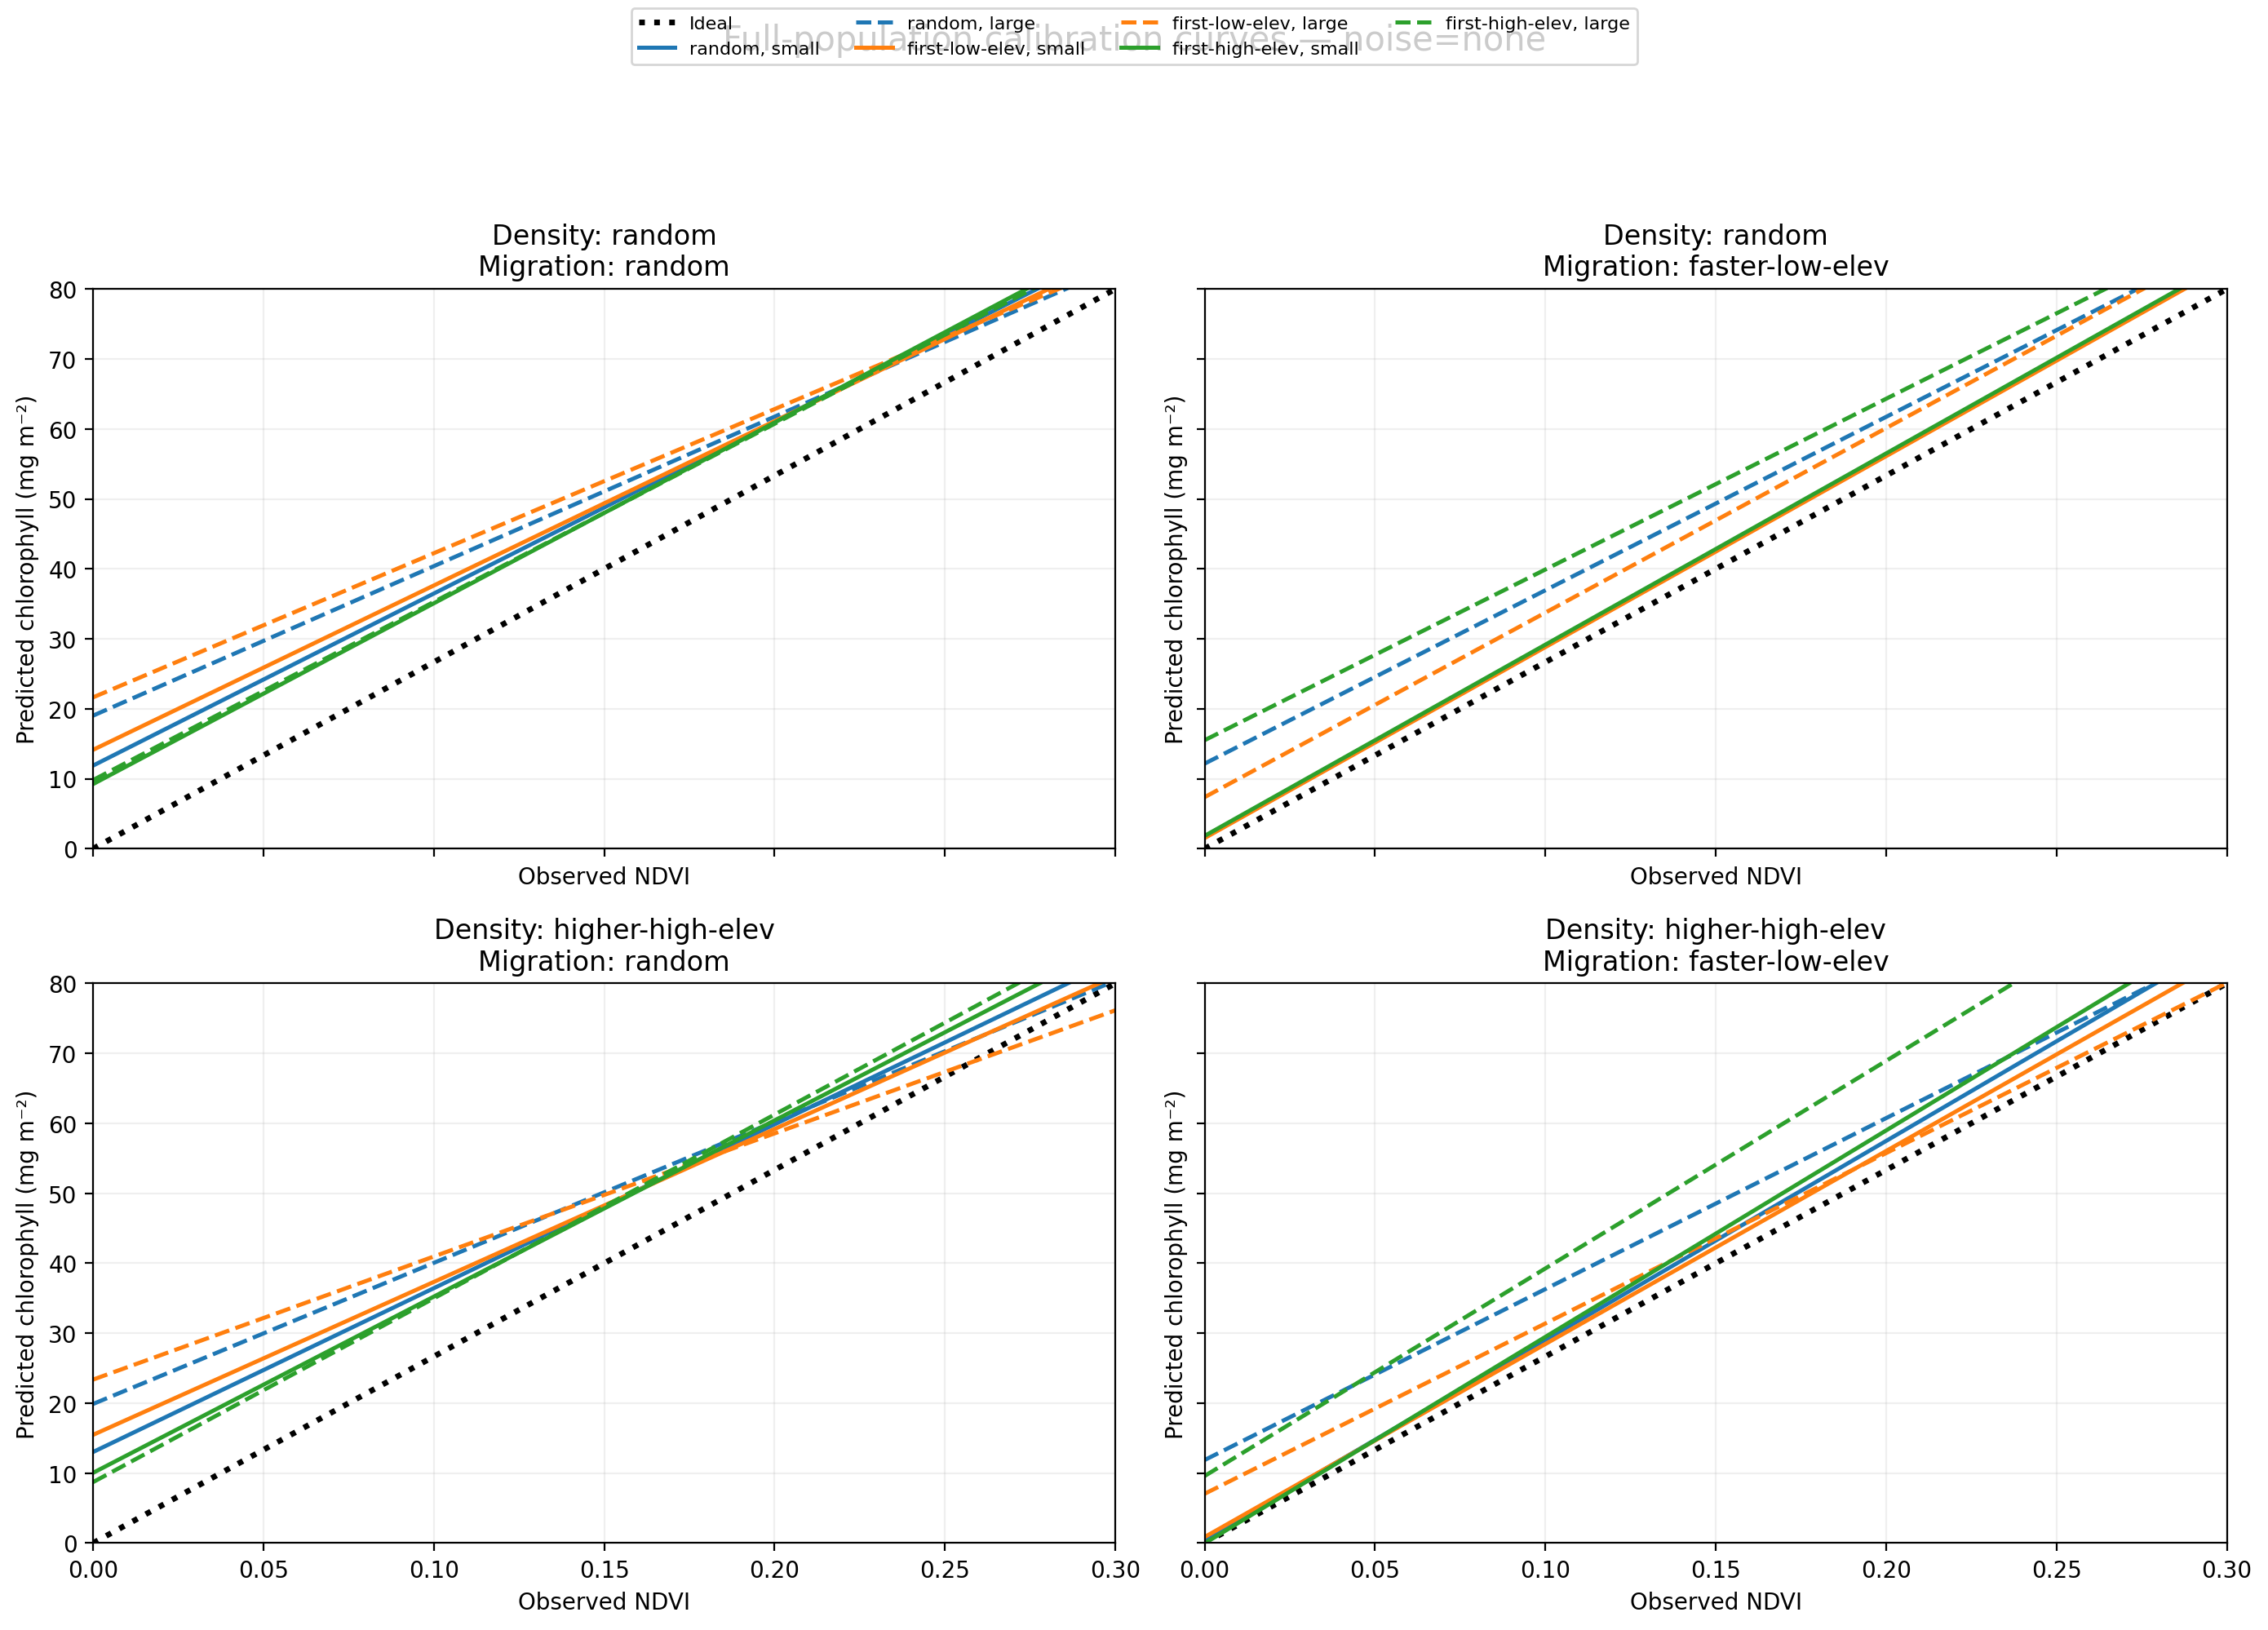

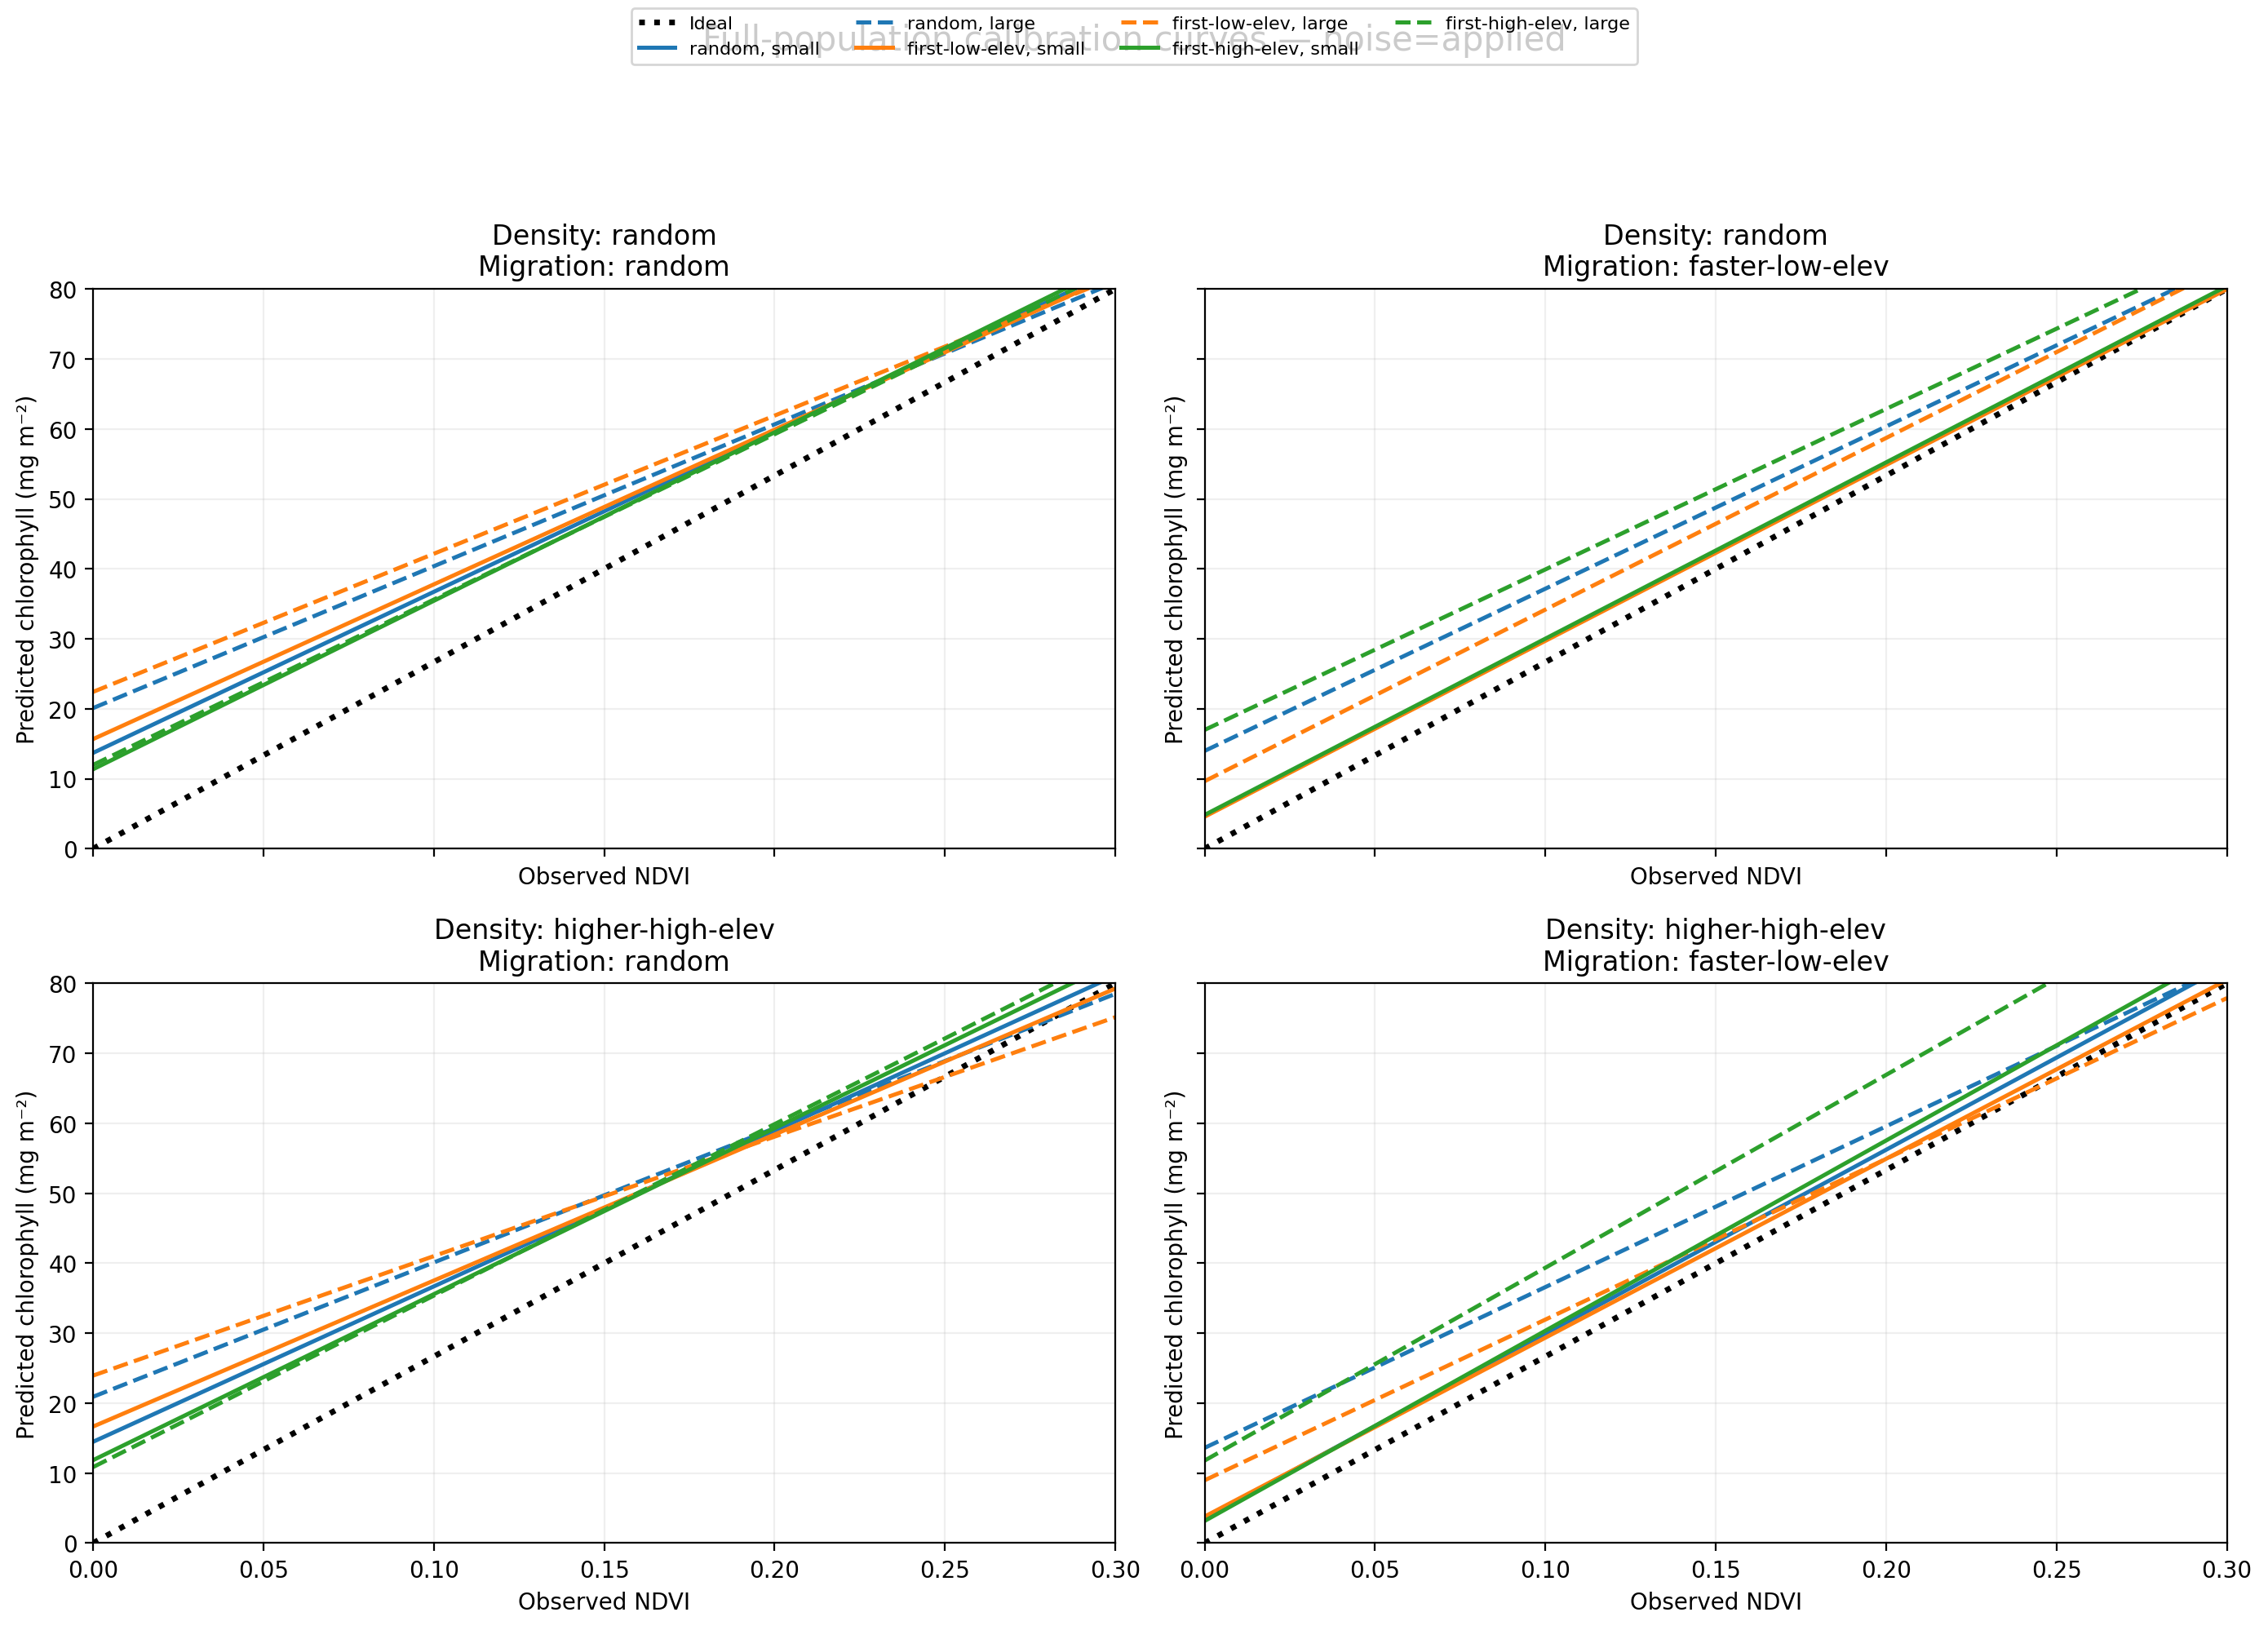

In [11]:

def final_fit(scenario):
    return fit_calibration(
        scenario["observed_ndvi"],
        scenario["observed_chla"],
    )


line_x = np.linspace(MIN_NDVI, MAX_NDVI, 200)

acquisition_colors = {
    "random": "tab:blue",
    "first-low-elev": "tab:orange",
    "first-high-elev": "tab:green",
}
window_styles = {
    "small": "-",
    "large": "--",
}

for noise_case in NOISE_CASES:
    fig, axes = plt.subplots(
        2, 2, figsize=(14, 10),
        sharex=True, sharey=True,
    )

    for row, density_case in enumerate(DENSITY_CASES):
        for column, migration_case in enumerate(
            MIGRATION_CASES
        ):
            axis = axes[row, column]

            axis.plot(
                line_x,
                ideal_slope * line_x + ideal_intercept,
                color="black",
                linestyle=":",
                linewidth=2.5,
                label="Ideal",
            )

            for acquisition_case in ACQUISITION_CASES:
                for window_case in WINDOW_CASES:
                    sid = scenario_id(
                        density_case,
                        migration_case,
                        acquisition_case,
                        window_case,
                        noise_case,
                    )
                    fit = final_fit(scenario_data[sid])

                    axis.plot(
                        line_x,
                        fit["slope"] * line_x
                        + fit["intercept"],
                        color=acquisition_colors[
                            acquisition_case
                        ],
                        linestyle=window_styles[
                            window_case
                        ],
                        linewidth=1.8,
                        label=(
                            f"{acquisition_case}, "
                            f"{window_case}"
                        ),
                    )

            axis.set(
                title=(
                    f"Density: {density_case}\n"
                    f"Migration: {migration_case}"
                ),
                xlabel="Observed NDVI",
                ylabel="Predicted chlorophyll (mg m⁻²)",
                xlim=(MIN_NDVI, MAX_NDVI),
                ylim=(MIN_CHLA_MGM2, MAX_CHLA_MGM2),
            )
            axis.grid(alpha=0.2)

    handles, labels = axes[0, 0].get_legend_handles_labels()
    unique = dict(zip(labels, handles))

    fig.legend(
        unique.values(),
        unique.keys(),
        loc="upper center",
        ncol=4,
        fontsize=8,
    )
    fig.suptitle(
        f"Full-population calibration curves — noise={noise_case}",
        fontsize=15,
        y=0.99,
    )
    plt.tight_layout(rect=(0, 0, 1, 0.92))
    plt.show()


## Detailed stage disturbance for one example scenario

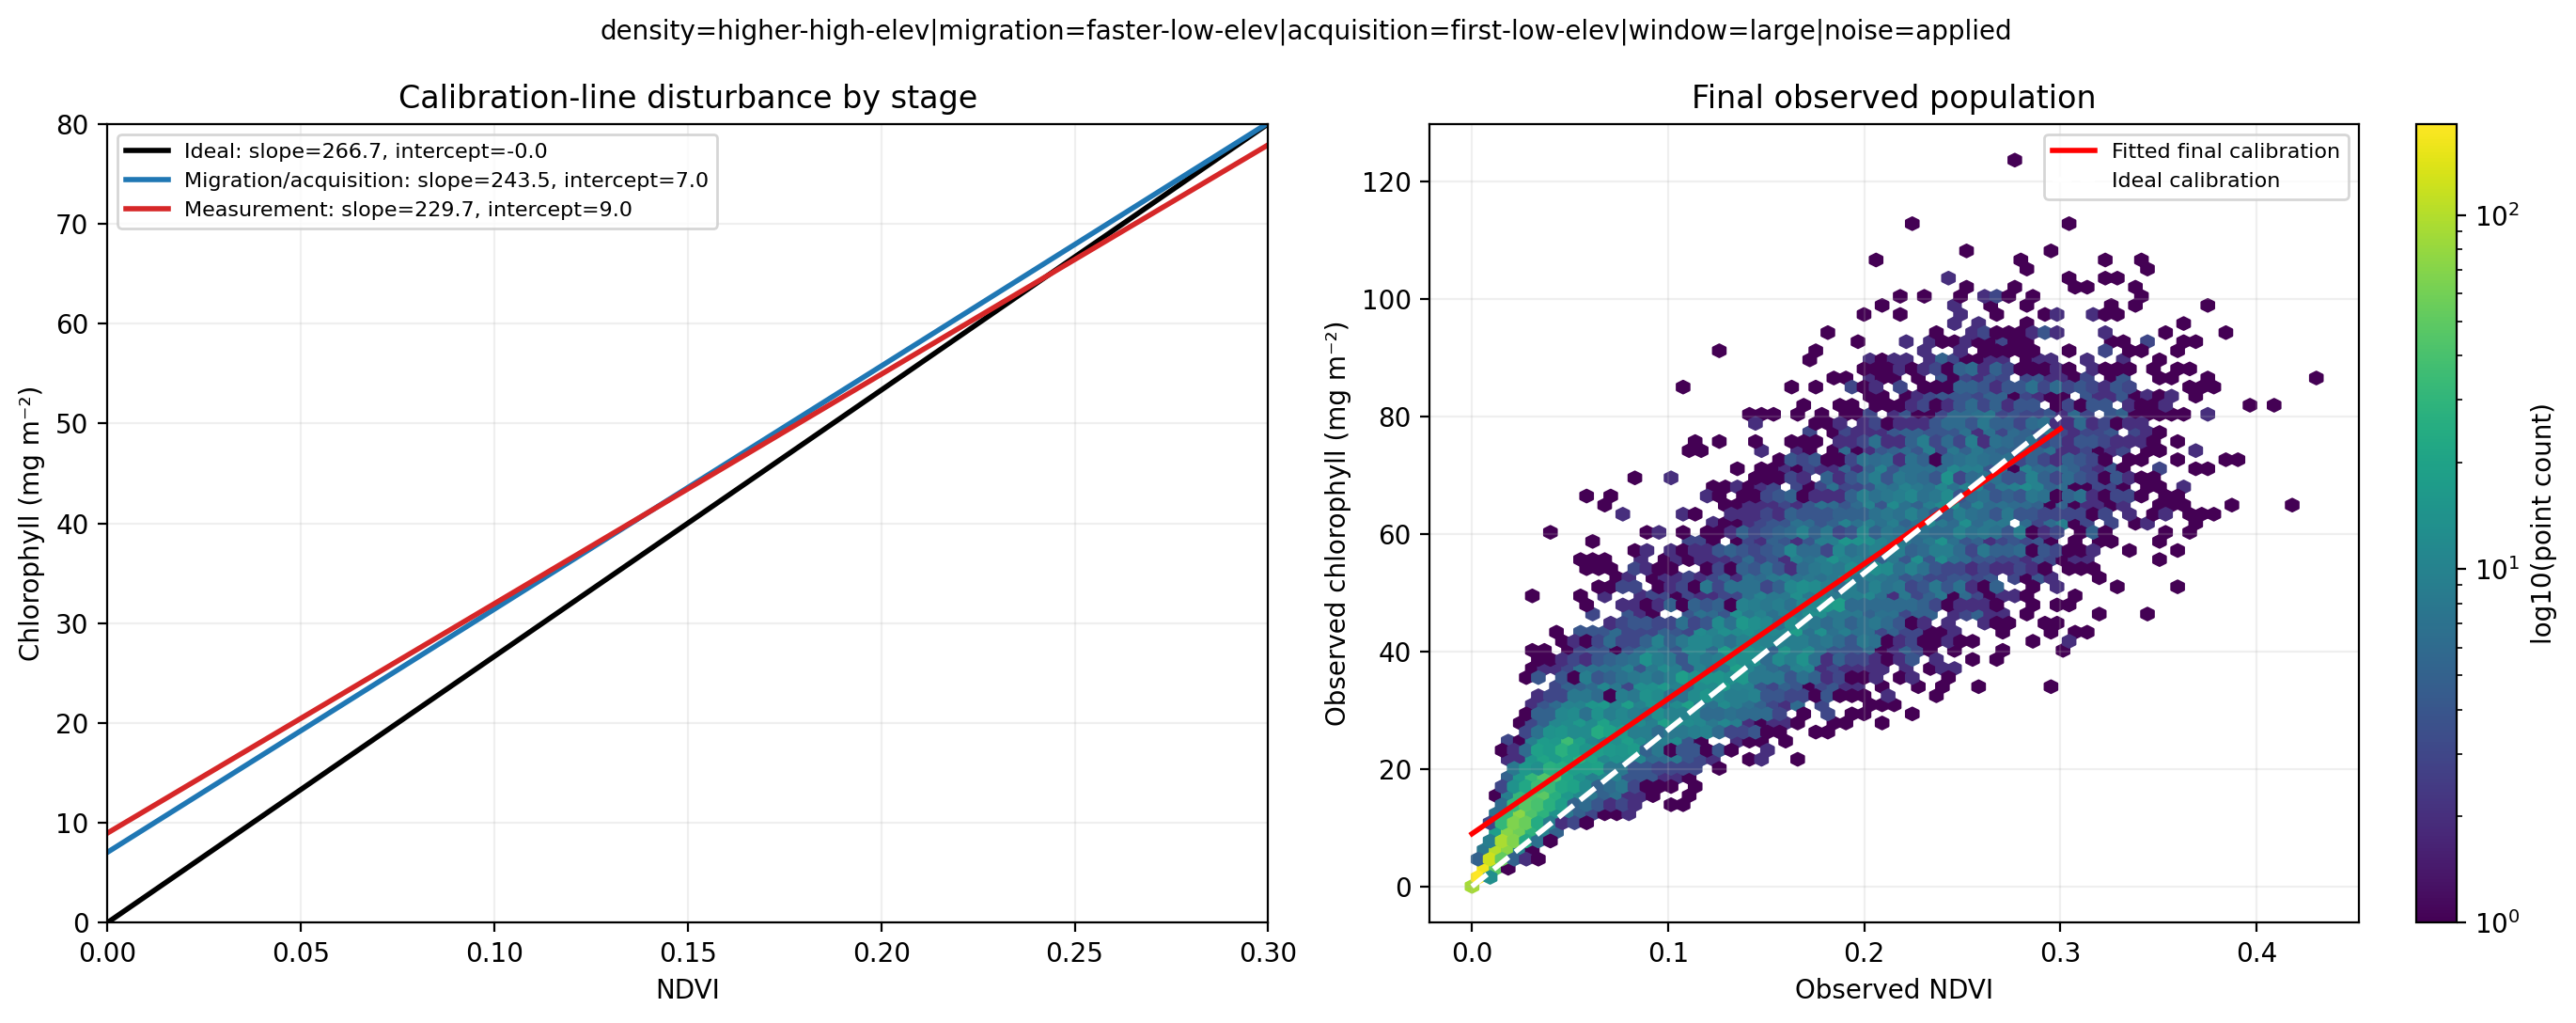

In [12]:

example_id = scenario_id(
    EXAMPLE_SCENARIO["density"],
    EXAMPLE_SCENARIO["migration"],
    EXAMPLE_SCENARIO["acquisition"],
    EXAMPLE_SCENARIO["window"],
    EXAMPLE_SCENARIO["noise"],
)
example = scenario_data[example_id]

stage_specs = [
    (
        "Ideal",
        example["ideal_ndvi"],
        example["true_chla"],
        "black",
    ),
    (
        "Migration/acquisition",
        example["migrated_ndvi"],
        example["true_chla"],
        "tab:blue",
    ),
    (
        "Measurement",
        example["observed_ndvi"],
        example["observed_chla"],
        "tab:red",
    ),
]

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

for label, x, fit_y, color in stage_specs:
    fit = fit_calibration(x, fit_y)

    axes[0].plot(
        line_x,
        fit["slope"] * line_x
        + fit["intercept"],
        color=color,
        linewidth=2,
        label=(
            f"{label}: slope={fit['slope']:.1f}, "
            f"intercept={fit['intercept']:.1f}"
        ),
    )

axes[0].set(
    title="Calibration-line disturbance by stage",
    xlabel="NDVI",
    ylabel="Chlorophyll (mg m⁻²)",
    xlim=(MIN_NDVI, MAX_NDVI),
    ylim=(MIN_CHLA_MGM2, MAX_CHLA_MGM2),
)
axes[0].grid(alpha=0.2)
axes[0].legend(fontsize=8)

hexbin = axes[1].hexbin(
    example["observed_ndvi"],
    example["observed_chla"],
    gridsize=70,
    bins="log",
    cmap="viridis",
    mincnt=1,
)

fit = final_fit(example)

axes[1].plot(
    line_x,
    fit["slope"] * line_x
    + fit["intercept"],
    color="red",
    linewidth=2,
    label="Fitted final calibration",
)
axes[1].plot(
    line_x,
    ideal_slope * line_x + ideal_intercept,
    color="white",
    linestyle="--",
    linewidth=2,
    label="Ideal calibration",
)
axes[1].set(
    title="Final observed population",
    xlabel="Observed NDVI",
    ylabel="Observed chlorophyll (mg m⁻²)",
)
axes[1].grid(alpha=0.2)
axes[1].legend(fontsize=8)

fig.colorbar(
    hexbin,
    ax=axes[1],
    label="log10(point count)",
)
fig.suptitle(example_id, fontsize=10)
plt.tight_layout()
plt.show()


## Repeated calibration subsampling

In [13]:

def fit_sample(x, y, indexes):
    sample_x = x[indexes]
    sample_y = y[indexes]

    if (
        len(sample_x) < 2
        or np.isclose(sample_x.var(), 0)
    ):
        return np.nan, np.nan

    slope, intercept = np.polyfit(
        sample_x,
        sample_y,
        1,
    )

    return float(slope), float(intercept)


subsample_records = []

for scenario_number, (sid, scenario) in enumerate(
    scenario_data.items()
):
    x = scenario["observed_ndvi"]
    fit_y = scenario["observed_chla"]
    true_y = scenario["true_chla"]

    moments = prediction_moments(x, true_y)

    rng = np.random.default_rng(
        RANDOM_SEED + 10_000 + scenario_number
    )

    for sample_size in SAMPLE_SIZES:
        for repetition in range(N_REPETITIONS):
            indexes = rng.choice(
                N_POINTS,
                size=sample_size,
                replace=False,
            )

            slope, intercept = fit_sample(
                x,
                fit_y,
                indexes,
            )

            if not np.isfinite(slope):
                continue

            metrics = evaluate_from_moments(
                slope,
                intercept,
                moments,
            )

            subsample_records.append(
                {
                    "scenario_id": sid,
                    "density": scenario["density"],
                    "migration": scenario["migration"],
                    "acquisition": scenario["acquisition"],
                    "window": scenario["window"],
                    "noise": scenario["noise"],
                    "sample_size": sample_size,
                    "repetition": repetition,
                    "slope": slope,
                    "intercept": intercept,
                    "slope_bias": slope - ideal_slope,
                    "intercept_bias": (
                        intercept - ideal_intercept
                    ),
                    "calibration_curve_rmse": curve_rmse(
                        slope, intercept
                    ),
                    **metrics,
                }
            )

    if (
        scenario_number == len(scenario_data) - 1
        or (scenario_number + 1) % 8 == 0
    ):
        print(
            f"Sampling experiment: "
            f"{scenario_number + 1}/"
            f"{len(scenario_data)} scenarios"
        )

df_subsample_results = pd.DataFrame(subsample_records)

print(
    f"Subsample fits: {len(df_subsample_results):,}"
)
display(df_subsample_results.head())


Sampling experiment: 8/48 scenarios
Sampling experiment: 16/48 scenarios
Sampling experiment: 24/48 scenarios
Sampling experiment: 32/48 scenarios
Sampling experiment: 40/48 scenarios
Sampling experiment: 48/48 scenarios
Subsample fits: 312,000


,scenario_id,density,migration,acquisition,window,noise,sample_size,repetition,slope,intercept,slope_bias,intercept_bias,calibration_curve_rmse,bias,rmse,r_squared
0,density=random|migration=random|acquisition=ra...,random,random,random,small,none,10,0,227.251427,15.359402,-39.415240,15.359402,10.048751,1.354180,12.657385,0.698130
1,density=random|migration=random|acquisition=ra...,random,random,random,small,none,10,1,368.916590,7.671240,102.249923,7.671240,24.664493,9.792515,18.593955,0.348557
2,density=random|migration=random|acquisition=ra...,random,random,random,small,none,10,2,312.743541,2.204661,46.076874,2.204661,9.956616,-2.068541,13.715646,0.645542
3,density=random|migration=random|acquisition=ra...,random,random,random,small,none,10,3,220.736953,13.687467,-45.929713,13.687467,7.882890,-1.059332,12.699149,0.696134
4,density=random|migration=random|acquisition=ra...,random,random,random,small,none,10,4,288.304914,4.825750,21.638247,4.825750,8.287576,-2.229430,13.126049,0.675361


In [14]:

subsample_summary = (
    df_subsample_results.groupby(
        ["scenario_id", "sample_size"],
        observed=True,
    )
    .agg(
        slope_median=("slope", "median"),
        slope_q025=(
            "slope",
            lambda x: x.quantile(0.025),
        ),
        slope_q25=(
            "slope",
            lambda x: x.quantile(0.25),
        ),
        slope_q75=(
            "slope",
            lambda x: x.quantile(0.75),
        ),
        slope_q975=(
            "slope",
            lambda x: x.quantile(0.975),
        ),
        rmse_median=("rmse", "median"),
        rmse_q025=(
            "rmse",
            lambda x: x.quantile(0.025),
        ),
        rmse_q975=(
            "rmse",
            lambda x: x.quantile(0.975),
        ),
        bias_median=("bias", "median"),
        bias_q025=(
            "bias",
            lambda x: x.quantile(0.025),
        ),
        bias_q975=(
            "bias",
            lambda x: x.quantile(0.975),
        ),
    )
    .reset_index()
)

display(subsample_summary.head())


,scenario_id,sample_size,slope_median,slope_q025,slope_q25,slope_q75,slope_q975,rmse_median,rmse_q025,rmse_q975,bias_median,bias_q025,bias_q975
0,density=higher-high-elev|migration=faster-low-...,10,286.549787,106.965624,235.978525,344.680777,486.039880,15.911721,14.842423,24.632506,0.618562,-8.526551,13.080830
1,density=higher-high-elev|migration=faster-low-...,20,280.538011,177.576767,244.089158,319.562331,401.118147,15.361605,14.799854,18.656775,0.585590,-6.248092,8.695858
2,density=higher-high-elev|migration=faster-low-...,30,274.457940,198.608831,249.323474,305.396601,369.436113,15.123529,14.789417,17.115729,-0.111141,-5.804717,6.850413
3,density=higher-high-elev|migration=faster-low-...,40,273.742137,201.380430,248.371103,297.103269,360.920984,15.037021,14.785494,16.567562,0.186327,-4.521714,5.766452
4,density=higher-high-elev|migration=faster-low-...,50,275.268014,212.349529,252.390577,302.855529,354.118786,15.041015,14.788010,16.472582,0.187084,-4.392924,5.338813


## Sample-size convergence for the example scenario

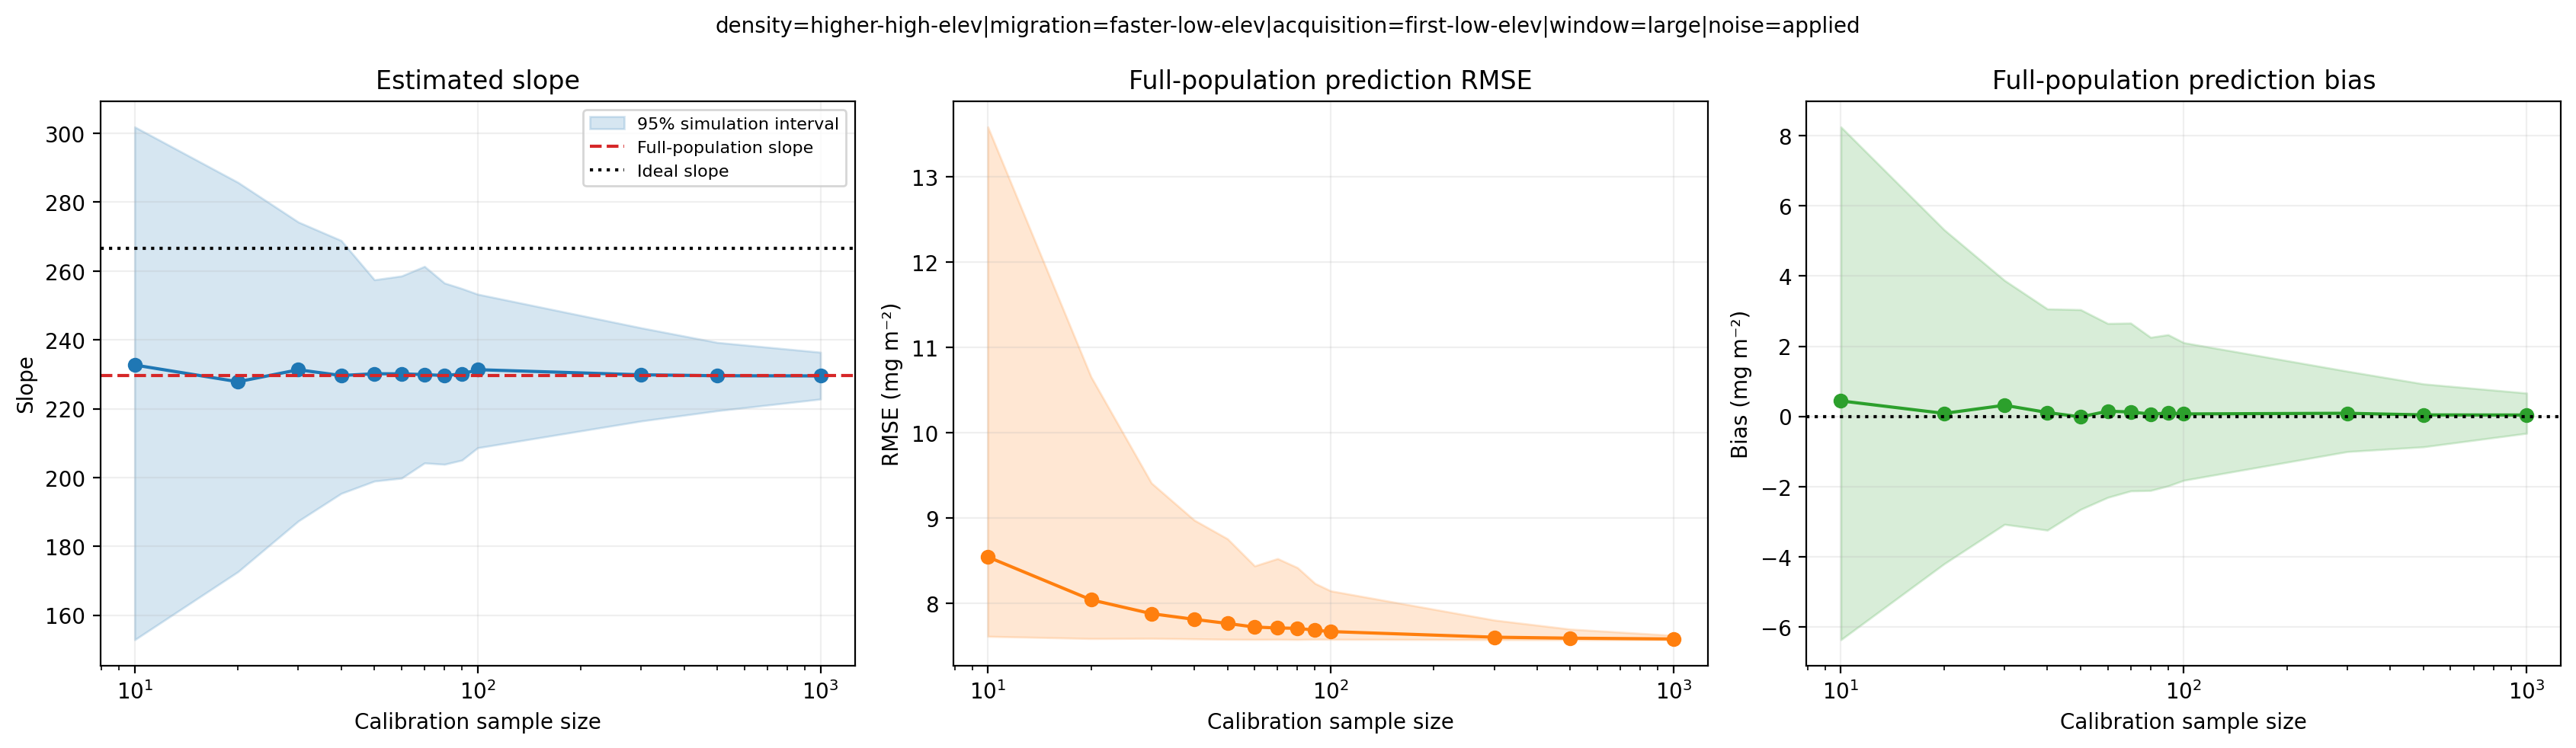

In [15]:

example_sampling = subsample_summary.loc[
    subsample_summary["scenario_id"] == example_id
].copy()

example_full_fit = final_fit(example)

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

axes[0].plot(
    example_sampling["sample_size"],
    example_sampling["slope_median"],
    marker="o",
    color="tab:blue",
)
axes[0].fill_between(
    example_sampling["sample_size"],
    example_sampling["slope_q025"],
    example_sampling["slope_q975"],
    color="tab:blue",
    alpha=0.18,
    label="95% simulation interval",
)
axes[0].axhline(
    example_full_fit["slope"],
    color="tab:red",
    linestyle="--",
    label="Full-population slope",
)
axes[0].axhline(
    ideal_slope,
    color="black",
    linestyle=":",
    label="Ideal slope",
)
axes[0].set(
    title="Estimated slope",
    xlabel="Calibration sample size",
    ylabel="Slope",
    xscale="log",
)
axes[0].grid(alpha=0.2)
axes[0].legend(fontsize=8)

axes[1].plot(
    example_sampling["sample_size"],
    example_sampling["rmse_median"],
    marker="o",
    color="tab:orange",
)
axes[1].fill_between(
    example_sampling["sample_size"],
    example_sampling["rmse_q025"],
    example_sampling["rmse_q975"],
    color="tab:orange",
    alpha=0.18,
)
axes[1].set(
    title="Full-population prediction RMSE",
    xlabel="Calibration sample size",
    ylabel="RMSE (mg m⁻²)",
    xscale="log",
)
axes[1].grid(alpha=0.2)

axes[2].plot(
    example_sampling["sample_size"],
    example_sampling["bias_median"],
    marker="o",
    color="tab:green",
)
axes[2].fill_between(
    example_sampling["sample_size"],
    example_sampling["bias_q025"],
    example_sampling["bias_q975"],
    color="tab:green",
    alpha=0.18,
)
axes[2].axhline(
    0,
    color="black",
    linestyle=":",
)
axes[2].set(
    title="Full-population prediction bias",
    xlabel="Calibration sample size",
    ylabel="Bias (mg m⁻²)",
    xscale="log",
)
axes[2].grid(alpha=0.2)

fig.suptitle(example_id, fontsize=10)
plt.tight_layout()
plt.show()


## Cross-acquisition-regime calibration transfer

In [16]:

def regime_label(acquisition, window):
    return f"{acquisition}|{window}"


transfer_records = []

for density_case, migration_case, noise_case in product(
    DENSITY_CASES,
    MIGRATION_CASES,
    NOISE_CASES,
):
    regimes = list(
        product(ACQUISITION_CASES, WINDOW_CASES)
    )

    for calibration_acquisition, calibration_window in regimes:
        calibration_id = scenario_id(
            density_case,
            migration_case,
            calibration_acquisition,
            calibration_window,
            noise_case,
        )
        calibration = scenario_data[calibration_id]
        fit = final_fit(calibration)

        for application_acquisition, application_window in regimes:
            application_id = scenario_id(
                density_case,
                migration_case,
                application_acquisition,
                application_window,
                noise_case,
            )
            application = scenario_data[application_id]

            metrics = evaluate_predictions(
                fit["slope"],
                fit["intercept"],
                application["observed_ndvi"],
                application["true_chla"],
            )

            transfer_records.append(
                {
                    "density": density_case,
                    "migration": migration_case,
                    "noise": noise_case,
                    "calibration_regime": regime_label(
                        calibration_acquisition,
                        calibration_window,
                    ),
                    "application_regime": regime_label(
                        application_acquisition,
                        application_window,
                    ),
                    "calibration_slope": fit["slope"],
                    "calibration_intercept": fit["intercept"],
                    **metrics,
                }
            )

df_transfer_results = pd.DataFrame(transfer_records)
display(df_transfer_results.head())


,density,migration,noise,calibration_regime,application_regime,calibration_slope,calibration_intercept,bias,rmse,mae,r_squared
0,random,random,none,random|small,random|small,245.943525,11.877401,-1.818989e-14,12.498493,9.571879,0.705661
1,random,random,none,random|small,random|large,245.943525,11.877401,-3.991517e+00,16.560550,12.078530,0.483248
2,random,random,none,random|small,first-low-elev|small,245.943525,11.877401,-1.043454e+00,13.744017,10.245227,0.644074
3,random,random,none,random|small,first-low-elev|large,245.943525,11.877401,-6.219662e+00,18.336797,13.407761,0.366452
4,random,random,none,random|small,first-high-elev|small,245.943525,11.877401,1.166355e+00,11.095269,8.839288,0.768043


## Transfer RMSE heatmaps

/tmp/ipykernel_20505/2316214539.py:104: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=(0, 0, 0.97, 0.93))


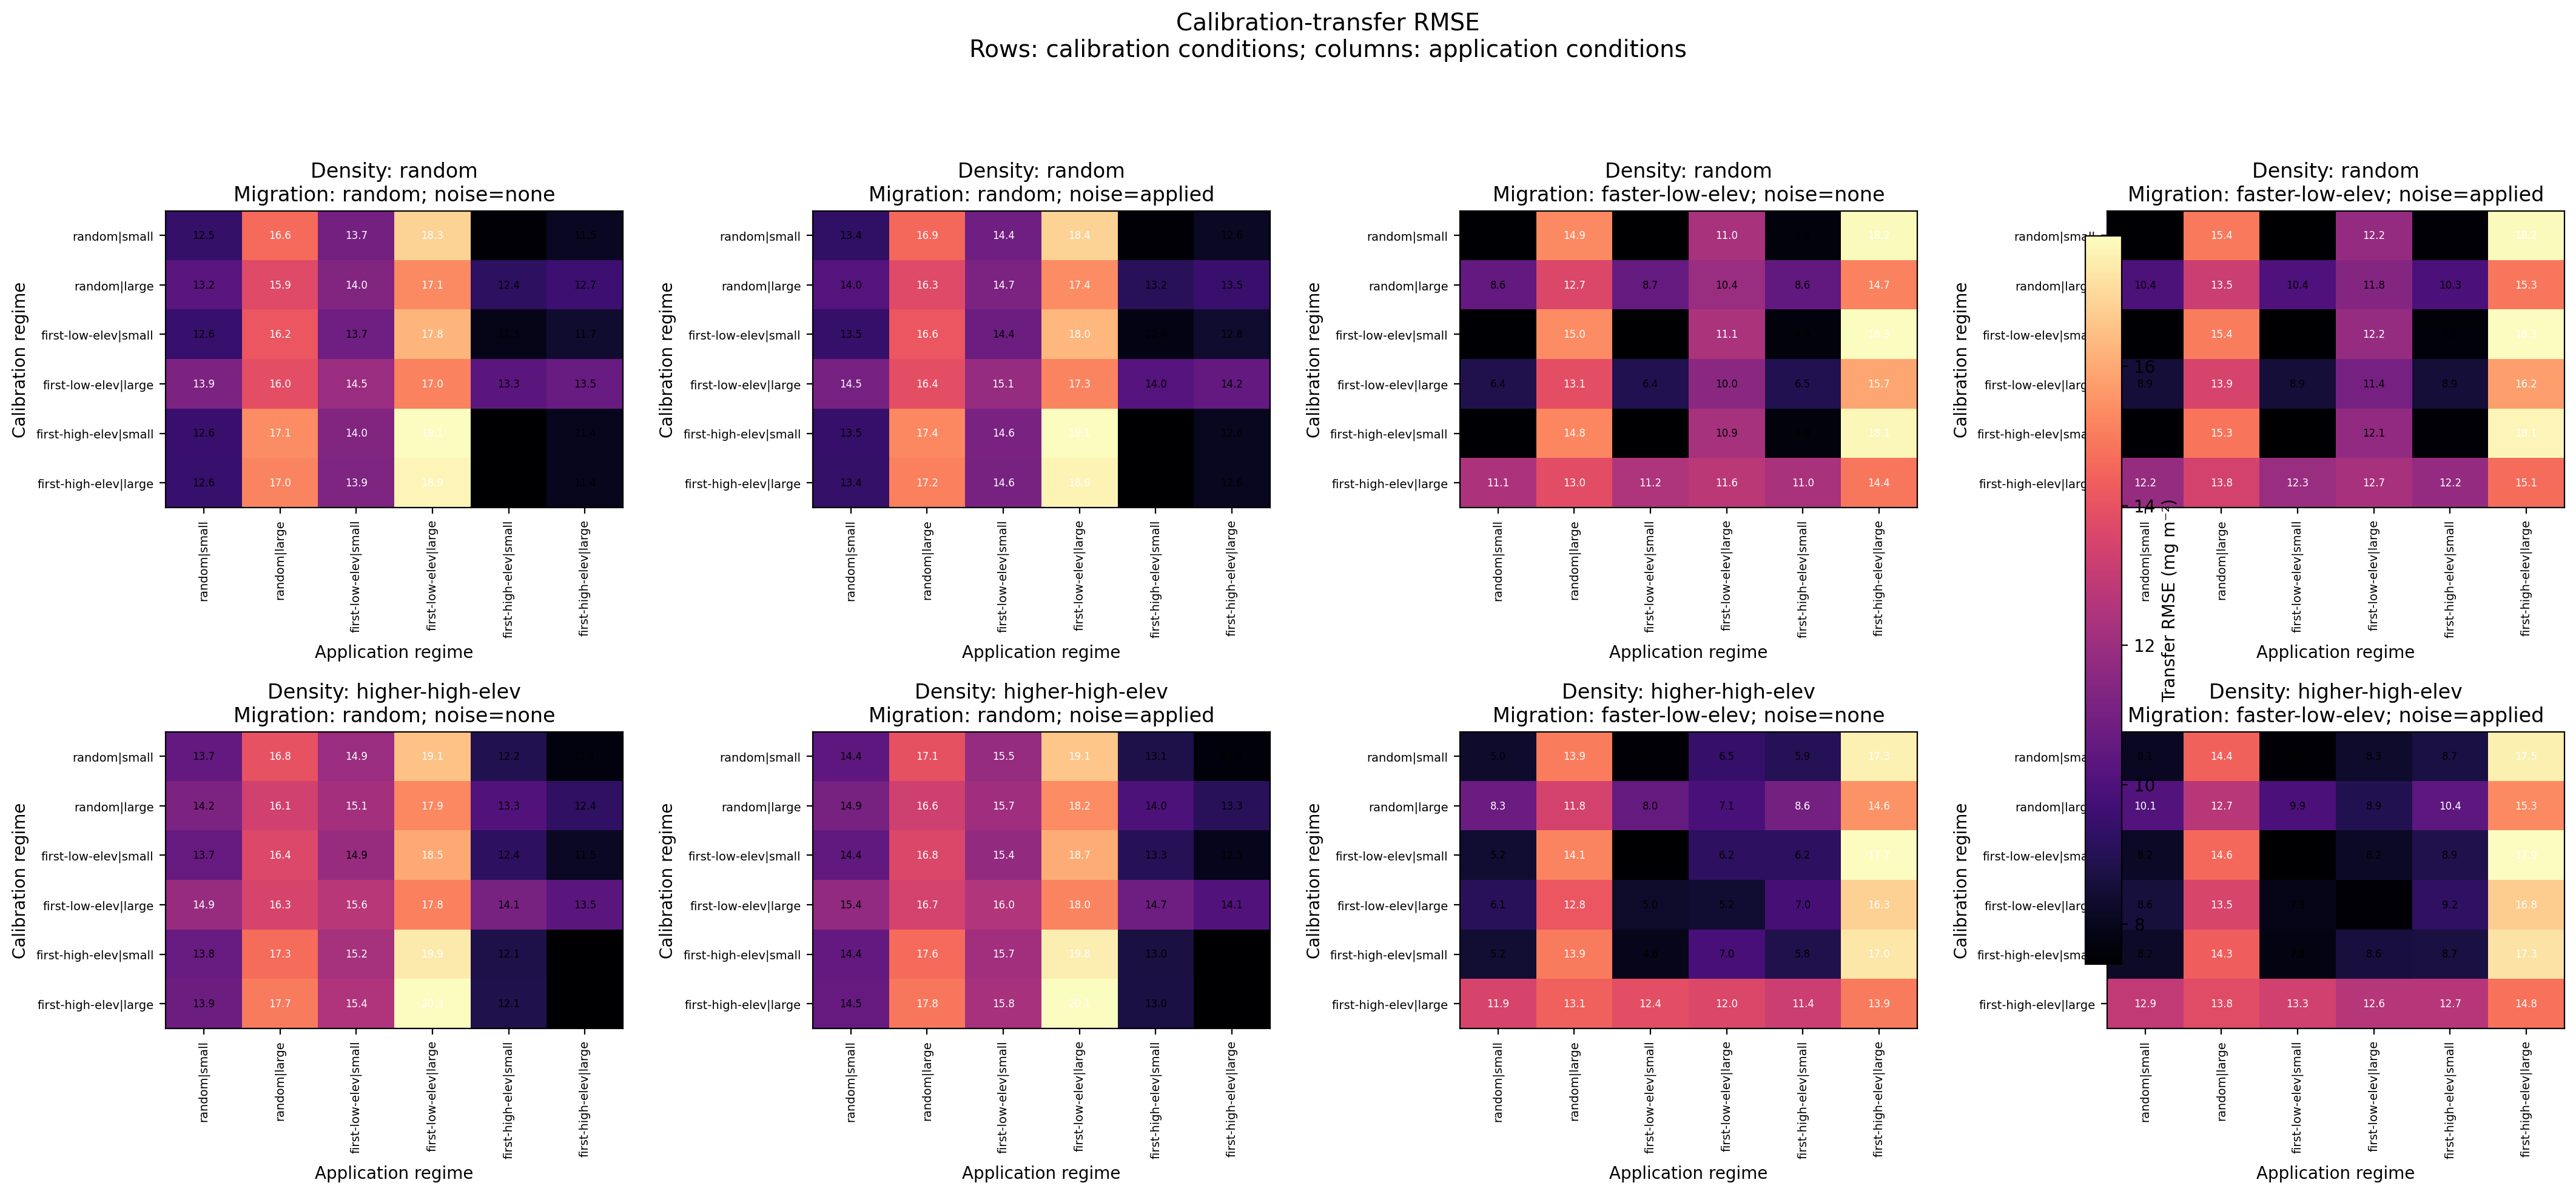

In [17]:

regime_order = [
    regime_label(acquisition, window)
    for acquisition, window in product(
        ACQUISITION_CASES,
        WINDOW_CASES,
    )
]

fig, axes = plt.subplots(
    2, 4, figsize=(22, 10)
)

for axis, (
    density_case,
    migration_case,
    noise_case,
) in zip(
    axes.ravel(),
    product(
        DENSITY_CASES,
        MIGRATION_CASES,
        NOISE_CASES,
    ),
):
    subset = df_transfer_results.loc[
        (df_transfer_results["density"] == density_case)
        & (
            df_transfer_results["migration"]
            == migration_case
        )
        & (df_transfer_results["noise"] == noise_case)
    ]

    matrix = (
        subset.pivot(
            index="calibration_regime",
            columns="application_regime",
            values="rmse",
        )
        .reindex(
            index=regime_order,
            columns=regime_order,
        )
    )

    image = axis.imshow(
        matrix.to_numpy(),
        cmap="magma",
        aspect="auto",
    )

    axis.set_xticks(
        range(len(regime_order)),
        regime_order,
        rotation=90,
        fontsize=7,
    )
    axis.set_yticks(
        range(len(regime_order)),
        regime_order,
        fontsize=7,
    )
    axis.set(
        title=(
            f"Density: {density_case}\n"
            f"Migration: {migration_case}; "
            f"noise={noise_case}"
        ),
        xlabel="Application regime",
        ylabel="Calibration regime",
    )

    threshold = np.nanmedian(matrix.to_numpy())

    for row in range(len(regime_order)):
        for column in range(len(regime_order)):
            value = matrix.iloc[row, column]
            axis.text(
                column,
                row,
                f"{value:.1f}",
                ha="center",
                va="center",
                fontsize=6,
                color=(
                    "white"
                    if value > threshold
                    else "black"
                ),
            )

fig.colorbar(
    image,
    ax=axes,
    shrink=0.78,
    label="Transfer RMSE (mg m⁻²)",
)
fig.suptitle(
    "Calibration-transfer RMSE\n"
    "Rows: calibration conditions; "
    "columns: application conditions",
    fontsize=14,
)
plt.tight_layout(rect=(0, 0, 0.97, 0.93))
plt.show()


## Scenario metric table

In [18]:

final_population_metrics = (
    df_stage_metrics.loc[
        df_stage_metrics["stage"] == "measurement"
    ]
    .sort_values(
        [
            "noise",
            "density",
            "migration",
            "acquisition",
            "window",
        ]
    )
)

display(
    final_population_metrics[
        [
            "scenario_id",
            "slope",
            "intercept",
            "slope_bias",
            "intercept_bias",
            "calibration_curve_rmse",
            "rmse",
            "mae",
            "bias",
            "r_squared",
            "mean_exposure",
            "min_exposure",
            "max_exposure",
            "mean_migration_fraction",
        ]
    ]
)


,scenario_id,slope,intercept,slope_bias,intercept_bias,calibration_curve_rmse,rmse,mae,bias,r_squared,mean_exposure,min_exposure,max_exposure,mean_migration_fraction
143,density=higher-high-elev|migration=faster-low-...,275.682939,11.790141,9.016272,11.790141,13.165912,14.777009,11.997817,6.764846e-02,0.588561,3.5,2.09808,10.508724,0.668785
137,density=higher-high-elev|migration=faster-low-...,271.913414,3.160050,5.246747,3.160050,3.973303,8.669782,6.480341,6.764846e-02,0.858372,3.5,1.00100,13.011712,0.930285
131,density=higher-high-elev|migration=faster-low-...,229.747905,8.970749,-36.918762,8.970749,4.698473,7.574201,5.923404,6.764846e-02,0.891905,3.5,1.00100,16.144831,0.825449
125,density=higher-high-elev|migration=faster-low-...,255.689850,3.787478,-10.976816,3.787478,2.343799,7.424599,5.546070,6.764846e-02,0.896133,3.5,1.00100,14.004850,0.939360
119,density=higher-high-elev|migration=faster-low-...,229.818228,13.608677,-36.848438,13.608677,8.692563,12.726898,10.103455,6.764846e-02,0.694805,3.5,1.00100,15.769269,0.747396
113,density=higher-high-elev|migration=faster-low-...,263.328548,3.551324,-3.338119,3.551324,3.064364,8.115375,6.070060,6.764846e-02,0.875906,3.5,1.00100,13.391190,0.936103
107,density=higher-high-elev|migration=random|acqu...,245.089958,10.860908,-21.576709,10.860908,7.851524,12.052617,9.540299,6.764846e-02,0.726287,3.5,2.09808,10.508724,0.789446
101,density=higher-high-elev|migration=random|acqu...,237.273763,11.849323,-29.392904,11.849323,7.866520,13.014970,9.554992,6.764846e-02,0.680832,3.5,1.00100,13.011712,0.790377
95,density=higher-high-elev|migration=random|acqu...,170.768659,23.939159,-95.898007,23.939159,12.677567,18.020555,13.625445,6.764846e-02,0.388116,3.5,1.00100,16.144831,0.591535
89,density=higher-high-elev|migration=random|acqu...,208.707176,16.653159,-57.959491,16.653159,9.418713,15.410144,11.205712,6.764846e-02,0.552548,3.5,1.00100,14.004850,0.730627



## Interpretation notes

- `true_chla` is unaffected by migration.
- NDVI is multiplied by the migration fraction.
- Measurement noise is multiplicative and equal to 15% of the actual value.
- Noisy chlorophyll is clipped only at zero.
- NDVI is not clipped after noise.
- The full-population calibration estimates systematic scenario bias.
- The sampling experiment fits each subset and evaluates it against the full
  10,000-point target population.
- Transfer matrices fit a calibration under one acquisition regime and apply it
  to another while holding density distribution, migration distribution, and
  noise fixed.
- Gaussian noise is added to elevation-based rankings so spatial relationships
  are not perfectly monotonic.
- Acquisition timing is adjusted to keep mean exposure close to 3.5 hours while
  guaranteeing exposure greater than one hour.
- `N_REPETITIONS = 500` can be reduced for development runs.


## End